In [ ]:

%pip install -q pandas numpy matplotlib seaborn scikit-learn textblob plotly streamlit


In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report
from textblob import TextBlob

print("Libraries imported successfully!")


Libraries imported successfully!


In [ ]:

data = {
    "content_id": [1, 2, 3, 4, 5, 6, 7, 8],
    "topic": [
        "Social Anxiety", "Dating", "Self Confidence",
        "Social Anxiety", "Dating", "Self Confidence",
        "Mental Health", "Mental Health"
    ],
    "format": [
        "Short", "Short", "Long", "Long",
        "Short", "Short", "Long", "Short"
    ],
    "views": [10000, 8000, 12000, 9000, 11000, 7000, 15000, 6000],
    "likes": [800, 700, 900, 600, 850, 500, 1000, 450],
    "shares": [150, 90, 200, 110, 140, 80, 250, 70],
    "saves": [220, 120, 350, 160, 190, 100, 400, 90]
}

df = pd.DataFrame(data)

df


,content_id,topic,format,views,likes,shares,saves
0,1,Social Anxiety,Short,10000,800,150,220
1,2,Dating,Short,8000,700,90,120
2,3,Self Confidence,Long,12000,900,200,350
3,4,Social Anxiety,Long,9000,600,110,160
4,5,Dating,Short,11000,850,140,190
5,6,Self Confidence,Short,7000,500,80,100
6,7,Mental Health,Long,15000,1000,250,400
7,8,Mental Health,Short,6000,450,70,90


In [ ]:

df["engagement_rate"] = (
    (df["likes"] + df["shares"] + df["saves"])
    / df["views"].replace(0, np.nan)
) * 100

df["save_to_share_ratio"] = (
    df["saves"] / df["shares"].replace(0, np.nan)
)

df[[
    "content_id",
    "topic",
    "views",
    "engagement_rate",
    "save_to_share_ratio"
]].round(2)


,content_id,topic,views,engagement_rate,save_to_share_ratio
0,1,Social Anxiety,10000,11.70,1.47
1,2,Dating,8000,11.38,1.33
2,3,Self Confidence,12000,12.08,1.75
3,4,Social Anxiety,9000,9.67,1.45
4,5,Dating,11000,10.73,1.36
5,6,Self Confidence,7000,9.71,1.25
6,7,Mental Health,15000,11.00,1.60
7,8,Mental Health,6000,10.17,1.29


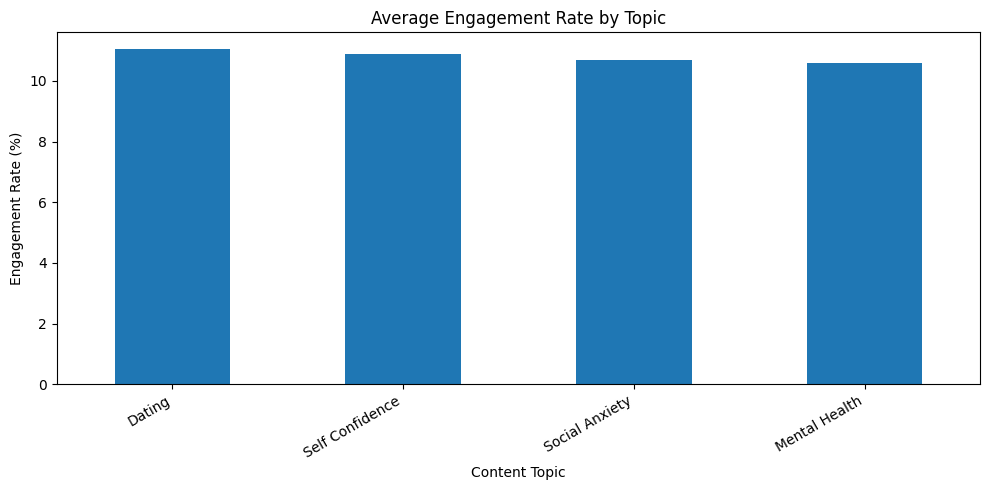

In [ ]:

topic_engagement = (
    df.groupby("topic")["engagement_rate"]
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(10, 5))
topic_engagement.plot(kind="bar")
plt.title("Average Engagement Rate by Topic")
plt.xlabel("Content Topic")
plt.ylabel("Engagement Rate (%)")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()


In [ ]:

# PHASE 2.1: Dataset inspection

print("Dataset shape (rows, columns):", df.shape)

print("\nFirst 5 records:")
display(df.head())

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nDataset information:")
df.info()

print("\nStatistical summary:")
display(df.describe(include="all"))


Dataset shape (rows, columns): (8, 9)

First 5 records:


,content_id,topic,format,views,likes,shares,saves,engagement_rate,save_to_share_ratio
0,1,Social Anxiety,Short,10000,800,150,220,11.700000,1.466667
1,2,Dating,Short,8000,700,90,120,11.375000,1.333333
2,3,Self Confidence,Long,12000,900,200,350,12.083333,1.750000
3,4,Social Anxiety,Long,9000,600,110,160,9.666667,1.454545
4,5,Dating,Short,11000,850,140,190,10.727273,1.357143



Column names:
['content_id', 'topic', 'format', 'views', 'likes', 'shares', 'saves', 'engagement_rate', 'save_to_share_ratio']

Data types:
content_id               int64
topic                   object
format                  object
views                    int64
likes                    int64
shares                   int64
saves                    int64
engagement_rate        float64
save_to_share_ratio    float64
dtype: object

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8 entries, 0 to 7
Data columns (total 9 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   content_id           8 non-null      int64  
 1   topic                8 non-null      object 
 2   format               8 non-null      object 
 3   views                8 non-null      int64  
 4   likes                8 non-null      int64  
 5   shares               8 non-null      int64  
 6   saves                8 non-null      in

,content_id,topic,format,views,likes,shares,saves,engagement_rate,save_to_share_ratio
count,8.00000,8,8,8.000000,8.000000,8.000000,8.000000,8.000000,8.000000
unique,NaN,4,2,NaN,NaN,NaN,NaN,NaN,NaN
top,NaN,Social Anxiety,Short,NaN,NaN,NaN,NaN,NaN,NaN
freq,NaN,2,5,NaN,NaN,NaN,NaN,NaN,NaN
mean,4.50000,NaN,NaN,9750.000000,725.000000,136.250000,203.750000,10.804153,1.437175
std,2.44949,NaN,NaN,2915.475947,196.396101,62.777953,115.255926,0.902144,0.169329
min,1.00000,NaN,NaN,6000.000000,450.000000,70.000000,90.000000,9.666667,1.250000
25%,2.75000,NaN,NaN,7750.000000,575.000000,87.500000,115.000000,10.053571,1.321429
50%,4.50000,NaN,NaN,9500.000000,750.000000,125.000000,175.000000,10.863636,1.405844
75%,6.25000,NaN,NaN,11250.000000,862.500000,162.500000,252.500000,11.456250,1.500000


In [ ]:

# PHASE 2.2: Data quality checks

print("Missing values per column:")
display(df.isnull().sum())

print("Total missing values:", df.isnull().sum().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nDuplicate content IDs:", df["content_id"].duplicated().sum())

print("\nNegative numeric values:")
numeric_df = df.select_dtypes(include="number")
display((numeric_df < 0).sum())

print("\nRecords with zero or negative views:")
display(df[df["views"] <= 0])


Missing values per column:


,0
content_id,0
topic,0
format,0
views,0
likes,0
shares,0
saves,0
engagement_rate,0
save_to_share_ratio,0


Total missing values: 0

Duplicate rows: 0

Duplicate content IDs: 0

Negative numeric values:


,0
content_id,0
views,0
likes,0
shares,0
saves,0
engagement_rate,0
save_to_share_ratio,0



Records with zero or negative views:


,content_id,topic,format,views,likes,shares,saves,engagement_rate,save_to_share_ratio


In [ ]:

# PHASE 2.3: Data cleaning

clean_df = df.copy()

# Remove accidental spaces from text columns
for col in clean_df.select_dtypes(include="object").columns:
    clean_df[col] = clean_df[col].str.strip()

# Convert metric columns to numeric values
metric_cols = ["views", "likes", "shares", "saves"]

for col in metric_cols:
    clean_df[col] = pd.to_numeric(
        clean_df[col], errors="coerce"
    )

# Remove duplicate content IDs, keeping the first record
clean_df = clean_df.drop_duplicates(
    subset=["content_id"], keep="first"
)

# Remove records missing essential identifiers or metrics
required_cols = ["content_id", "topic", "format"] + metric_cols
clean_df = clean_df.dropna(subset=required_cols)

# Keep records with valid, non-negative counts and positive views
valid_rows = (
    (clean_df[metric_cols] >= 0).all(axis=1)
    & (clean_df["views"] > 0)
)

clean_df = clean_df.loc[valid_rows].copy()

# Recalculate metrics from the cleaned counts
clean_df["engagement_rate"] = (
    (
        clean_df["likes"]
        + clean_df["shares"]
        + clean_df["saves"]
    ) / clean_df["views"]
) * 100

clean_df["save_to_share_ratio"] = (
    clean_df["saves"]
    / clean_df["shares"].replace(0, np.nan)
)

clean_df = clean_df.reset_index(drop=True)

print("Original records:", len(df))
print("Cleaned records:", len(clean_df))
print("Records removed:", len(df) - len(clean_df))

display(clean_df)


Original records: 8
Cleaned records: 8
Records removed: 0


,content_id,topic,format,views,likes,shares,saves,engagement_rate,save_to_share_ratio
0,1,Social Anxiety,Short,10000,800,150,220,11.700000,1.466667
1,2,Dating,Short,8000,700,90,120,11.375000,1.333333
2,3,Self Confidence,Long,12000,900,200,350,12.083333,1.750000
3,4,Social Anxiety,Long,9000,600,110,160,9.666667,1.454545
4,5,Dating,Short,11000,850,140,190,10.727273,1.357143
5,6,Self Confidence,Short,7000,500,80,100,9.714286,1.250000
6,7,Mental Health,Long,15000,1000,250,400,11.000000,1.600000
7,8,Mental Health,Short,6000,450,70,90,10.166667,1.285714


In [ ]:

# PHASE 2.4B: Topic analysis

topic_summary = (
    clean_df.groupby("topic")
    .agg(
        number_of_posts=("content_id", "count"),
        average_views=("views", "mean"),
        average_engagement=("engagement_rate", "mean"),
        total_shares=("shares", "sum"),
        total_saves=("saves", "sum")
    )
    .sort_values("average_engagement", ascending=False)
)

display(topic_summary.round(2))


,number_of_posts,average_views,average_engagement,total_shares,total_saves
topic,,,,,
Dating,2,9500.0,11.05,230,310
Self Confidence,2,9500.0,10.90,280,450
Social Anxiety,2,9500.0,10.68,260,380
Mental Health,2,10500.0,10.58,320,490


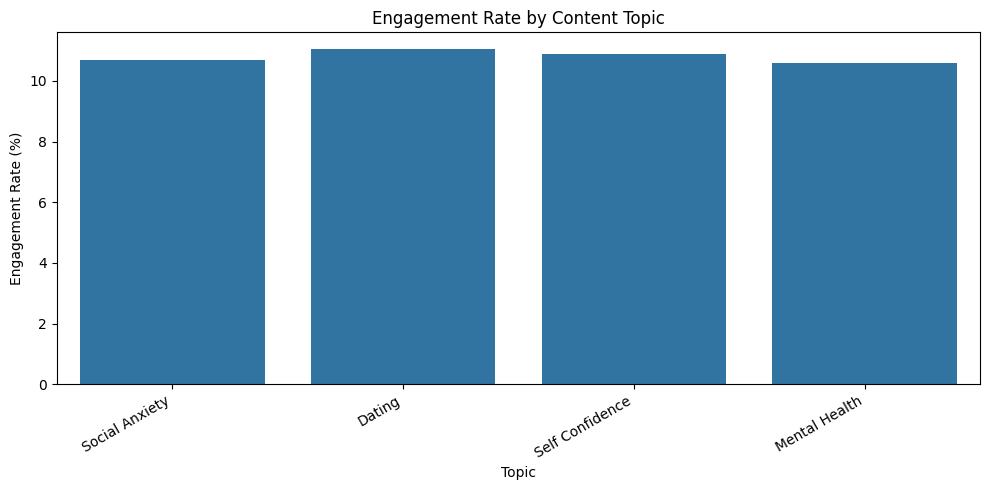

In [ ]:

# PHASE 2.4C: Engagement by topic

plt.figure(figsize=(10, 5))

sns.barplot(
    data=clean_df,
    x="topic",
    y="engagement_rate",
    errorbar=None
)

plt.title("Engagement Rate by Content Topic")
plt.xlabel("Topic")
plt.ylabel("Engagement Rate (%)")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()


,number_of_posts,average_views,average_engagement,average_shares,average_saves
format,,,,,
Long,3,12000.0,10.92,186.67,303.33
Short,5,8400.0,10.74,106.00,144.00


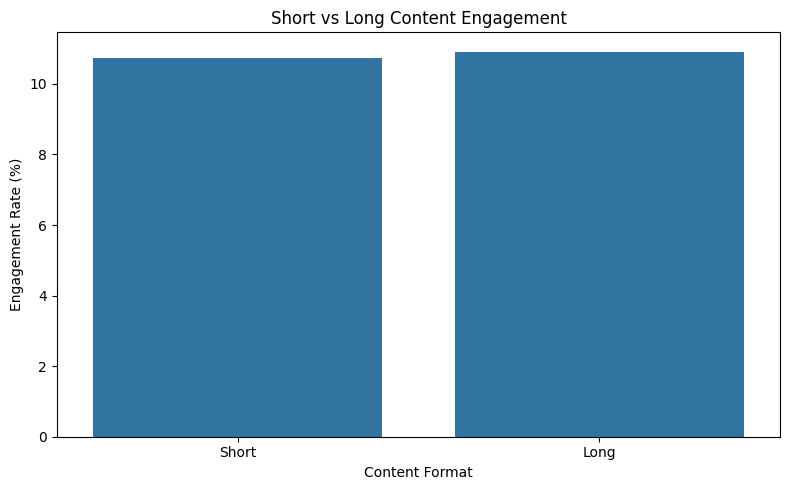

In [ ]:

# PHASE 2.4D: Format comparison

format_summary = (
    clean_df.groupby("format")
    .agg(
        number_of_posts=("content_id", "count"),
        average_views=("views", "mean"),
        average_engagement=("engagement_rate", "mean"),
        average_shares=("shares", "mean"),
        average_saves=("saves", "mean")
    )
)

display(format_summary.round(2))

plt.figure(figsize=(8, 5))

sns.barplot(
    data=clean_df,
    x="format",
    y="engagement_rate",
    errorbar=None
)

plt.title("Short vs Long Content Engagement")
plt.xlabel("Content Format")
plt.ylabel("Engagement Rate (%)")
plt.tight_layout()
plt.show()


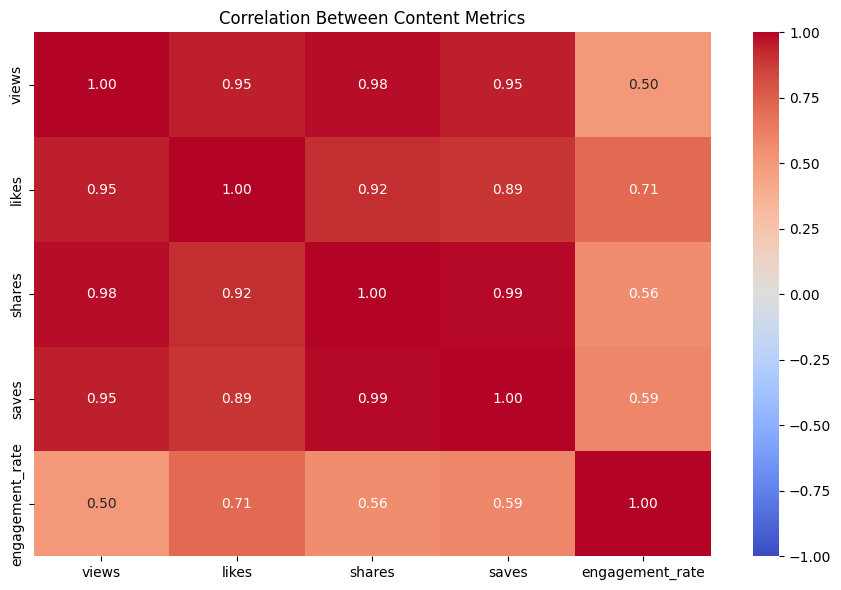

In [ ]:

# PHASE 2.4E: Correlation analysis

correlation_cols = [
    "views", "likes", "shares", "saves",
    "engagement_rate"
]

correlation_matrix = clean_df[correlation_cols].corr()

plt.figure(figsize=(9, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Between Content Metrics")
plt.tight_layout()
plt.show()


In [ ]:

# PHASE 2.5: Export cleaned data

output_path = "/content/cleaned_content_performance.csv"

clean_df.to_csv(output_path, index=False)

print("Cleaned dataset saved to:", output_path)

from google.colab import files
files.download(output_path)


Cleaned dataset saved to: /content/cleaned_content_performance.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

# PHASE 3.1: Create a sample comments dataset

comments_data = {
    "comment_id": list(range(1, 21)),
    "topic": [
        "Social Anxiety", "Social Anxiety", "Social Anxiety",
        "Dating", "Dating", "Dating",
        "Self Confidence", "Self Confidence",
        "Mental Health", "Mental Health",
        "Social Anxiety", "Dating",
        "Self Confidence", "Mental Health",
        "Social Anxiety", "Dating",
        "Mental Health", "Self Confidence",
        "Dating", "Social Anxiety"
    ],
    "comment": [
        "I thought I was the only one who felt this way",
        "This is so relatable, I experience this every day",
        "Very informative video",
        "This happened to me in my last relationship",
        "Nice video, keep going",
        "I feel understood after watching this",
        "I needed to hear this today",
        "Great content and explanation",
        "Nobody talks about this enough",
        "This helped me understand my feelings",
        "Interesting topic",
        "Why is this literally me",
        "I am trying to improve myself every day",
        "This describes exactly how I feel",
        "I always feel nervous in social situations",
        "Good video",
        "I do not feel alone anymore",
        "Thanks for sharing this message",
        "I have experienced the same thing",
        "Very useful information"
    ],
    "relatability_label": [
        "Relatable", "Relatable", "Neutral",
        "Relatable", "Neutral", "Relatable",
        "Relatable", "Neutral", "Relatable",
        "Relatable", "Neutral", "Relatable",
        "Relatable", "Relatable", "Relatable",
        "Neutral", "Relatable", "Neutral",
        "Relatable", "Neutral"
    ]
}

comments_df = pd.DataFrame(comments_data)

display(comments_df.head(10))
print("Total comments:", len(comments_df))
print("\nLabel distribution:")
display(comments_df["relatability_label"].value_counts())


,comment_id,topic,comment,relatability_label
0,1,Social Anxiety,I thought I was the only one who felt this way,Relatable
1,2,Social Anxiety,"This is so relatable, I experience this every day",Relatable
2,3,Social Anxiety,Very informative video,Neutral
3,4,Dating,This happened to me in my last relationship,Relatable
4,5,Dating,"Nice video, keep going",Neutral
5,6,Dating,I feel understood after watching this,Relatable
6,7,Self Confidence,I needed to hear this today,Relatable
7,8,Self Confidence,Great content and explanation,Neutral
8,9,Mental Health,Nobody talks about this enough,Relatable
9,10,Mental Health,This helped me understand my feelings,Relatable


Total comments: 20

Label distribution:


,count
relatability_label,
Relatable,13
Neutral,7


In [ ]:

# PHASE 3.2: Sentiment analysis

def get_sentiment(text):
    polarity = TextBlob(text).sentiment.polarity

    if polarity > 0.1:
        return "Positive"
    elif polarity < -0.1:
        return "Negative"
    else:
        return "Neutral"

comments_df["sentiment"] = (
    comments_df["comment"].apply(get_sentiment)
)

display(
    comments_df[
        ["comment", "sentiment", "relatability_label"]
    ].head(10)
)

print("\nSentiment distribution:")
display(comments_df["sentiment"].value_counts())


,comment,sentiment,relatability_label
0,I thought I was the only one who felt this way,Neutral,Relatable
1,"This is so relatable, I experience this every day",Neutral,Relatable
2,Very informative video,Positive,Neutral
3,This happened to me in my last relationship,Neutral,Relatable
4,"Nice video, keep going",Positive,Neutral
5,I feel understood after watching this,Neutral,Relatable
6,I needed to hear this today,Neutral,Relatable
7,Great content and explanation,Positive,Neutral
8,Nobody talks about this enough,Neutral,Relatable
9,This helped me understand my feelings,Neutral,Relatable



Sentiment distribution:


,count
sentiment,
Neutral,11
Positive,9


In [ ]:

# PHASE 3.3: Relatability classification

from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report

X = comments_df["comment"]
y = comments_df["relatability_label"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

relatability_model = Pipeline([
    ("tfidf", TfidfVectorizer(ngram_range=(1, 2))),
    ("classifier", LogisticRegression(max_iter=1000))
])

relatability_model.fit(X_train, y_train)

predictions = relatability_model.predict(X_test)

print("Classification report:")
print(classification_report(
    y_test,
    predictions,
    zero_division=0
))


Classification report:
              precision    recall  f1-score   support

     Neutral       0.00      0.00      0.00         2
   Relatable       0.67      1.00      0.80         4

    accuracy                           0.67         6
   macro avg       0.33      0.50      0.40         6
weighted avg       0.44      0.67      0.53         6



In [ ]:

new_comment = [
    "I thought I was the only person experiencing this"
]

predicted_label = relatability_model.predict(new_comment)[0]
predicted_sentiment = get_sentiment(new_comment[0])

print("Comment:", new_comment[0])
print("Predicted relatability:", predicted_label)
print("Estimated sentiment:", predicted_sentiment)


Comment: I thought I was the only person experiencing this
Predicted relatability: Relatable
Estimated sentiment: Neutral


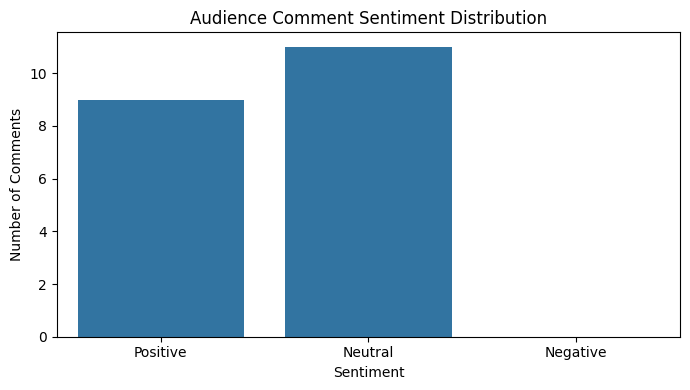

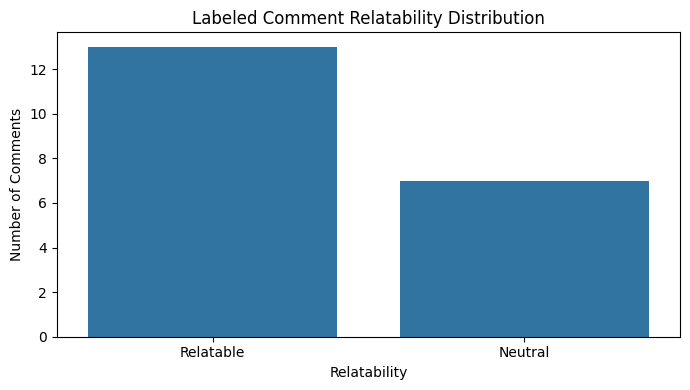

In [ ]:

# PHASE 3.5: Visualize comment labels

plt.figure(figsize=(7, 4))

sns.countplot(
    data=comments_df,
    x="sentiment",
    order=["Positive", "Neutral", "Negative"]
)

plt.title("Audience Comment Sentiment Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Number of Comments")
plt.tight_layout()
plt.show()

plt.figure(figsize=(7, 4))

sns.countplot(
    data=comments_df,
    x="relatability_label",
    order=["Relatable", "Neutral"]
)

plt.title("Labeled Comment Relatability Distribution")
plt.xlabel("Relatability")
plt.ylabel("Number of Comments")
plt.tight_layout()
plt.show()


In [ ]:

# Export analyzed comments

comments_df.to_csv(
    "/content/analyzed_comments.csv",
    index=False
)

from google.colab import files
files.download("/content/analyzed_comments.csv")

print("Analyzed comments exported successfully!")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Analyzed comments exported successfully!


In [ ]:

# PHASE 4.1: Define the target variable

model_df = clean_df.copy()

threshold = model_df["engagement_rate"].median()

model_df["performance_label"] = np.where(
    model_df["engagement_rate"] >= threshold,
    "High Performing",
    "Low Performing"
)

print("Median engagement threshold:", round(threshold, 2), "%")
display(
    model_df[
        ["content_id", "topic", "format",
         "engagement_rate", "performance_label"]
    ]
)

print("\nTarget distribution:")
display(model_df["performance_label"].value_counts())


Median engagement threshold: 10.86 %


,content_id,topic,format,engagement_rate,performance_label
0,1,Social Anxiety,Short,11.700000,High Performing
1,2,Dating,Short,11.375000,High Performing
2,3,Self Confidence,Long,12.083333,High Performing
3,4,Social Anxiety,Long,9.666667,Low Performing
4,5,Dating,Short,10.727273,Low Performing
5,6,Self Confidence,Short,9.714286,Low Performing
6,7,Mental Health,Long,11.000000,High Performing
7,8,Mental Health,Short,10.166667,Low Performing



Target distribution:


,count
performance_label,
High Performing,4
Low Performing,4


In [ ]:

# PHASE 4.2: Prepare model features

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression

feature_cols = ["topic", "format", "views"]
target_col = "performance_label"

X = model_df[feature_cols]
y = model_df[target_col]

print("Features:")
display(X.head())

print("\nTarget labels:")
display(y.head())


Features:


,topic,format,views
0,Social Anxiety,Short,10000
1,Dating,Short,8000
2,Self Confidence,Long,12000
3,Social Anxiety,Long,9000
4,Dating,Short,11000



Target labels:


,performance_label
0,High Performing
1,High Performing
2,High Performing
3,Low Performing
4,Low Performing


In [ ]:

# PHASE 4.3: Build and train the demonstration model

categorical_features = ["topic", "format"]
numeric_features = ["views"]

preprocessor = ColumnTransformer([
    (
        "categorical",
        Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("encoder", OneHotEncoder(handle_unknown="ignore"))
        ]),
        categorical_features
    ),
    (
        "numeric",
        Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler())
        ]),
        numeric_features
    )
])

virality_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000))
])

virality_model.fit(X, y)

print("Demonstration model trained successfully!")


Demonstration model trained successfully!


In [ ]:

# PHASE 4.4: Test a new content item

new_content = pd.DataFrame({
    "topic": ["Social Anxiety"],
    "format": ["Short"],
    "views": [10000]
})

predicted_class = virality_model.predict(new_content)[0]
probabilities = virality_model.predict_proba(new_content)[0]

print("New content:")
display(new_content)

print("Predicted performance:", predicted_class)

for label, probability in zip(
    virality_model.classes_, probabilities
):
    print(f"{label}: {probability:.2%}")


New content:


,topic,format,views
0,Social Anxiety,Short,10000


Predicted performance: High Performing
High Performing: 51.69%
Low Performing: 48.31%


In [ ]:

# PHASE 4.5: Save demonstration predictions

prediction_results = new_content.copy()
prediction_results["predicted_performance"] = predicted_class

for label, probability in zip(
    virality_model.classes_, probabilities
):
    safe_label = label.lower().replace(" ", "_")
    prediction_results[f"probability_{safe_label}"] = probability

display(prediction_results)

prediction_results.to_csv(
    "/content/virality_prediction_demo.csv",
    index=False
)

print("Prediction results saved successfully!")


,topic,format,views,predicted_performance,probability_high_performing,probability_low_performing
0,Social Anxiety,Short,10000,High Performing,0.516927,0.483073


Prediction results saved successfully!


In [ ]:

import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import ttest_ind

# Illustrative data for demonstrating A/B testing
ab_df = pd.DataFrame({
    "post_id": range(1, 13),
    "version": [
        "A", "A", "A", "A", "A", "A",
        "B", "B", "B", "B", "B", "B"
    ],
    "views": [
        1000, 1200, 1100, 950, 1300, 1050,
        1000, 1200, 1100, 950, 1300, 1050
    ],
    "likes": [
        80, 96, 77, 76, 104, 84,
        100, 132, 110, 95, 143, 105
    ],
    "shares": [
        10, 12, 11, 9, 13, 10,
        15, 18, 16, 14, 20, 16
    ],
    "saves": [
        8, 10, 9, 7, 11, 8,
        12, 15, 13, 11, 17, 12
    ]
})

ab_df["engagement_rate"] = (
    (ab_df["likes"] + ab_df["shares"] + ab_df["saves"])
    / ab_df["views"]
) * 100

display(ab_df)


,post_id,version,views,likes,shares,saves,engagement_rate
0,1,A,1000,80,10,8,9.800000
1,2,A,1200,96,12,10,9.833333
2,3,A,1100,77,11,9,8.818182
3,4,A,950,76,9,7,9.684211
4,5,A,1300,104,13,11,9.846154
5,6,A,1050,84,10,8,9.714286
6,7,B,1000,100,15,12,12.700000
7,8,B,1200,132,18,15,13.750000
8,9,B,1100,110,16,13,12.636364
9,10,B,950,95,14,11,12.631579


In [ ]:

ab_summary = ab_df.groupby("version").agg(
    number_of_posts=("post_id", "count"),
    average_views=("views", "mean"),
    average_engagement_rate=("engagement_rate", "mean")
).round(2)

display(ab_summary)


,number_of_posts,average_views,average_engagement_rate
version,,,
A,6,1100.0,9.62
B,6,1100.0,13.04


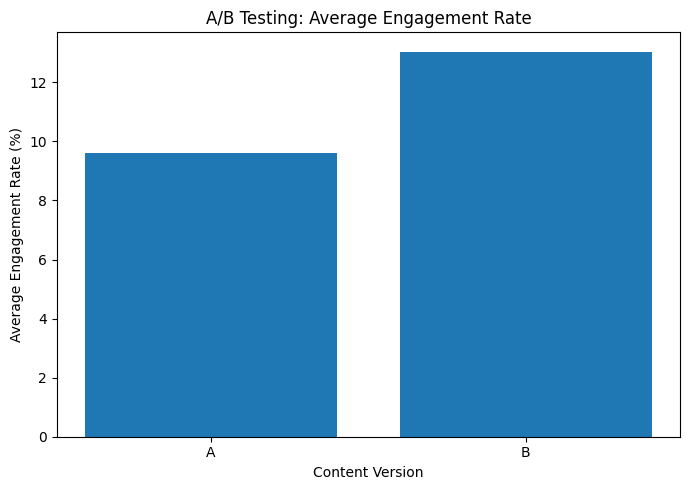

In [ ]:

plt.figure(figsize=(7, 5))

plt.bar(
    ab_summary.index,
    ab_summary["average_engagement_rate"]
)

plt.title("A/B Testing: Average Engagement Rate")
plt.xlabel("Content Version")
plt.ylabel("Average Engagement Rate (%)")
plt.tight_layout()
plt.show()


In [ ]:

version_a = ab_df.loc[
    ab_df["version"] == "A", "engagement_rate"
]

version_b = ab_df.loc[
    ab_df["version"] == "B", "engagement_rate"
]

t_statistic, p_value = ttest_ind(
    version_a,
    version_b,
    equal_var=False
)

print("T-statistic:", round(t_statistic, 4))
print("P-value:", round(p_value, 4))

if p_value < 0.05:
    print("The difference is statistically significant in this demonstration.")
else:
    print("The test does not show a statistically significant difference.")


T-statistic: -11.8002
P-value: 0.0
The difference is statistically significant in this demonstration.


In [ ]:

ab_df.to_csv("ab_testing_results.csv", index=False)
ab_summary.to_csv("ab_testing_summary.csv")

print("A/B testing files saved successfully!")


A/B testing files saved successfully!


In [ ]:

from google.colab import files

files.download("ab_testing_results.csv")
files.download("ab_testing_summary.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

# Phase 6: Content Recommendation System

import pandas as pd
import matplotlib.pyplot as plt

# Use the cleaned dataset created in Phase 2
recommendation_df = clean_df.copy()

# Check required columns
print("Available columns:")
print(recommendation_df.columns.tolist())

display(recommendation_df.head())


Available columns:
['content_id', 'topic', 'format', 'views', 'likes', 'shares', 'saves', 'engagement_rate', 'save_to_share_ratio']


,content_id,topic,format,views,likes,shares,saves,engagement_rate,save_to_share_ratio
0,1,Social Anxiety,Short,10000,800,150,220,11.700000,1.466667
1,2,Dating,Short,8000,700,90,120,11.375000,1.333333
2,3,Self Confidence,Long,12000,900,200,350,12.083333,1.750000
3,4,Social Anxiety,Long,9000,600,110,160,9.666667,1.454545
4,5,Dating,Short,11000,850,140,190,10.727273,1.357143


In [ ]:

topic_performance = (
    recommendation_df
    .groupby("topic")
    .agg(
        total_posts=("topic", "count"),
        average_engagement=("engagement_rate", "mean"),
        average_views=("views", "mean")
    )
    .sort_values("average_engagement", ascending=False)
    .round(2)
)

print("Topic Performance Ranking:")
display(topic_performance)


Topic Performance Ranking:


,total_posts,average_engagement,average_views
topic,,,
Dating,2,11.05,9500.0
Self Confidence,2,10.90,9500.0
Social Anxiety,2,10.68,9500.0
Mental Health,2,10.58,10500.0


In [ ]:

format_performance = (
    recommendation_df
    .groupby("format")
    .agg(
        total_posts=("format", "count"),
        average_engagement=("engagement_rate", "mean"),
        average_views=("views", "mean")
    )
    .sort_values("average_engagement", ascending=False)
    .round(2)
)

print("Content Format Ranking:")
display(format_performance)


Content Format Ranking:


,total_posts,average_engagement,average_views
format,,,
Long,3,10.92,12000.0
Short,5,10.74,8400.0


In [ ]:

best_topic = topic_performance.index[0]
best_format = format_performance.index[0]

print("CONTENT RECOMMENDATION REPORT")
print("-" * 35)

print(
    f"Recommended topic: {best_topic}"
)

print(
    f"Recommended format: {best_format}"
)

print(
    f"Average engagement for this topic: "
    f"{topic_performance.iloc[0]['average_engagement']:.2f}%"
)

print(
    f"Average engagement for this format: "
    f"{format_performance.iloc[0]['average_engagement']:.2f}%"
)

print(
    "\nRecommendation: Test content using the top-ranked "
    "topic and format, then compare its performance "
    "with your next posts."
)


CONTENT RECOMMENDATION REPORT
-----------------------------------
Recommended topic: Dating
Recommended format: Long
Average engagement for this topic: 11.05%
Average engagement for this format: 10.92%

Recommendation: Test content using the top-ranked topic and format, then compare its performance with your next posts.


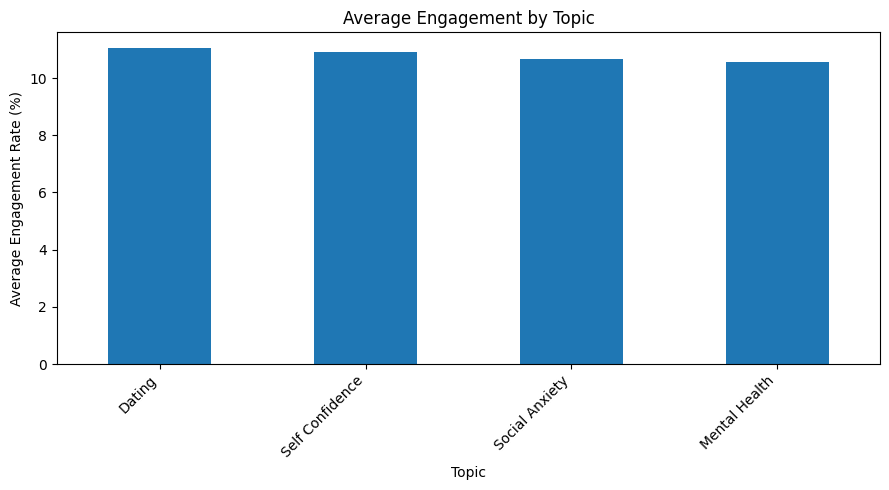

In [ ]:

topic_performance["average_engagement"].plot(
    kind="bar",
    figsize=(9, 5),
    title="Average Engagement by Topic"
)

plt.ylabel("Average Engagement Rate (%)")
plt.xlabel("Topic")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


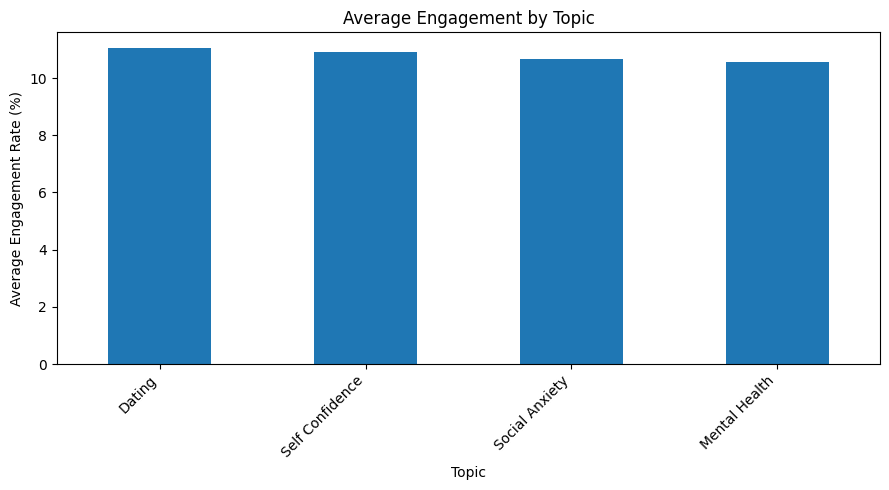

In [ ]:

topic_performance["average_engagement"].plot(
    kind="bar",
    figsize=(9, 5),
    title="Average Engagement by Topic"
)

plt.ylabel("Average Engagement Rate (%)")
plt.xlabel("Topic")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


In [ ]:
# Export recommendations to CSV first
topic_performance.to_csv("topic_recommendations.csv")
format_performance.to_csv("format_recommendations.csv")

# Now download the files
from google.colab import files

files.download("topic_recommendations.csv")
files.download("format_recommendations.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

!pip -q install streamlit pyngrok


In [ ]:

import os

files_to_check = [
    "cleaned_content_performance.csv",
    "analyzed_comments.csv",
    "virality_prediction_demo.csv",
    "ab_testing_results.csv",
    "ab_testing_summary.csv",
    "topic_recommendations.csv",
    "format_recommendations.csv"
]

print("PROJECT FILE CHECK")
print("-" * 35)

for filename in files_to_check:
    if os.path.exists("/content/" + filename):
        print("FOUND:", filename)
    else:
        print("NOT FOUND:", filename)


PROJECT FILE CHECK
-----------------------------------
FOUND: cleaned_content_performance.csv
FOUND: analyzed_comments.csv
FOUND: virality_prediction_demo.csv
FOUND: ab_testing_results.csv
FOUND: ab_testing_summary.csv
FOUND: topic_recommendations.csv
FOUND: format_recommendations.csv


In [ ]:

%%writefile app.py

import streamlit as st
import pandas as pd
import matplotlib.pyplot as plt
import os

st.set_page_config(
    page_title="Social Engagement Analytics",
    page_icon="📊",
    layout="wide"
)

st.title("📊 Data-Driven Social Engagement Initiative")
st.write(
    "Analyze content performance, audience sentiment, "
    "virality predictions, and content recommendations."
)

st.sidebar.header("Navigation")

page = st.sidebar.radio(
    "Choose a section",
    [
        "Overview",
        "Content Performance",
        "Sentiment Analysis",
        "Virality Predictions",
        "Recommendations"
    ]
)

def load_csv(filename):
    if os.path.exists(filename):
        return pd.read_csv(filename)
    return pd.DataFrame()

content_df = load_csv("cleaned_content_performance.csv")
comments_df = load_csv("analyzed_comments.csv")
virality_df = load_csv("virality_prediction_demo.csv")
topic_df = load_csv("topic_recommendations.csv")
format_df = load_csv("format_recommendations.csv")

if page == "Overview":
    st.subheader("Project Overview")

    if not content_df.empty:
        col1, col2, col3 = st.columns(3)

        col1.metric("Total Posts", len(content_df))

        if "views" in content_df.columns:
            col2.metric(
                "Total Views",
                f"{content_df['views'].sum():,.0f}"
            )
        else:
            col2.metric("Total Views", "Unavailable")

        if "engagement_rate" in content_df.columns:
            col3.metric(
                "Average Engagement",
                f"{content_df['engagement_rate'].mean():.2f}%"
            )
        else:
            col3.metric("Average Engagement", "Unavailable")

        st.dataframe(content_df, use_container_width=True)
    else:
        st.info(
            "Upload cleaned_content_performance.csv "
            "using the sidebar uploader below."
        )

elif page == "Content Performance":
    st.subheader("Content Performance Analysis")

    if not content_df.empty:
        st.dataframe(content_df, use_container_width=True)

        if {"topic", "engagement_rate"}.issubset(content_df.columns):
            chart_data = content_df.groupby(
                "topic"
            )["engagement_rate"].mean().sort_values(
                ascending=False
            )

            st.bar_chart(chart_data)
        else:
            st.warning(
                "The content dataset needs topic and "
                "engagement_rate columns for this chart."
            )
    else:
        st.warning("No content performance dataset loaded.")

elif page == "Sentiment Analysis":
    st.subheader("Audience Sentiment Analysis")

    if not comments_df.empty:
        st.dataframe(comments_df, use_container_width=True)

        if "sentiment" in comments_df.columns:
            st.write("Sentiment distribution")
            st.bar_chart(comments_df["sentiment"].value_counts())

        elif "relatability_label" in comments_df.columns:
            st.write("Relatability label distribution")
            st.bar_chart(
                comments_df["relatability_label"].value_counts()
            )
        else:
            st.info(
                "No sentiment or relatability label column "
                "was found in this dataset."
            )
    else:
        st.warning("No analyzed comments dataset loaded.")

elif page == "Virality Predictions":
    st.subheader("Virality Prediction Results")

    if not virality_df.empty:
        st.dataframe(virality_df, use_container_width=True)
        st.caption(
            "Demonstration predictions are not validated "
            "forecasts of real-world viral performance."
        )
    else:
        st.info(
            "No prediction output file is currently available."
        )

elif page == "Recommendations":
    st.subheader("Content Recommendations")

    col1, col2 = st.columns(2)

    with col1:
        st.write("Topic recommendations")
        if not topic_df.empty:
            st.dataframe(topic_df, use_container_width=True)
        else:
            st.info("Topic recommendation file not found.")

    with col2:
        st.write("Format recommendations")
        if not format_df.empty:
            st.dataframe(format_df, use_container_width=True)
        else:
            st.info("Format recommendation file not found.")

st.sidebar.divider()
st.sidebar.subheader("Upload project data")

uploaded_file = st.sidebar.file_uploader(
    "Upload a CSV dataset",
    type=["csv"]
)

if uploaded_file is not None:
    uploaded_df = pd.read_csv(uploaded_file)
    st.subheader(f"Uploaded Dataset: {uploaded_file.name}")
    st.dataframe(uploaded_df, use_container_width=True)

    st.download_button(
        "Download uploaded dataset",
        data=uploaded_df.to_csv(index=False),
        file_name="processed_dataset.csv",
        mime="text/csv"
    )


Writing app.py


In [ ]:

!streamlit run app.py --server.port 8501 > streamlit.log 2>&1 &


In [ ]:

!pip -q install streamlit
!npm install -g localtunnel


⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼
changed 22 packages in 4s
⠼
⠴3 packages are looking for funding
⠴  run `npm fund` for details
⠴

In [ ]:

import subprocess
import time
import requests

# Start Streamlit if it is not already running
streamlit_process = subprocess.Popen(
    [
        "streamlit", "run", "app.py",
        "--server.port", "8501",
        "--server.address", "0.0.0.0",
        "--server.headless", "true"
    ],
    stdout=subprocess.DEVNULL,
    stderr=subprocess.DEVNULL
)

time.sleep(5)

# Check whether the dashboard is responding
try:
    response = requests.get("http://127.0.0.1:8501", timeout=10)
    print("Dashboard server status:", response.status_code)
except Exception as error:
    print("Dashboard server is not responding:", error)


Dashboard server status: 200


In [ ]:

!lt --port 8501


your url is: https://smart-pumas-grow.loca.lt
^C


In [ ]:

report = r"""
# THE DATA-DRIVEN SOCIAL ENGAGEMENT INITIATIVE

## 1. Abstract
This project explores data-driven methods for analyzing
social media content performance. It demonstrates data
cleaning, exploratory data analysis, comment classification,
virality prediction, A/B testing, content recommendations,
and dashboard development.

## 2. Problem Statement
Content creators need a structured way to understand
engagement patterns and compare content strategies.
This project demonstrates a data science workflow to
support these decisions.

## 3. Objectives
- Analyze content performance metrics.
- Explore engagement patterns across topics and formats.
- Demonstrate comment sentiment and relatability analysis.
- Build a demonstration virality classification model.
- Compare content variations through A/B testing.
- Generate topic and format recommendations.
- Present analysis through an interactive dashboard.

## 4. Methodology
1. Environment setup and sample data creation.
2. Data cleaning and exploratory analysis.
3. Sentiment analysis and relatability classification.
4. Virality prediction.
5. A/B testing demonstration.
6. Content recommendation.
7. Streamlit dashboard development.

## 5. Technologies Used
- Python
- Google Colab
- Pandas and NumPy
- Matplotlib
- TextBlob
- Scikit-learn
- Streamlit

## 6. Implementation and Results
Insert actual screenshots, output tables, charts,
classification metrics, and dashboard results here.

Do not invent performance figures. Clearly identify
illustrative or synthetic datasets.

## 7. Limitations
The demonstration uses small illustrative datasets.
Its predictions and comparisons should not be treated
as validated real-world findings.

## 8. Future Scope
- Collect a larger representative dataset.
- Integrate authorized social media data sources.
- Validate models using appropriate evaluation methods.
- Conduct properly designed A/B experiments.
- Deploy the dashboard in a suitable hosting environment.

## 9. Conclusion
The project demonstrates how data analysis and machine
learning techniques can be combined to explore social
media engagement and support content strategy decisions.
"""

with open("/content/project_report_template.md", "w") as f:
    f.write(report)

print("Report template created successfully!")


Report template created successfully!


In [ ]:

from google.colab import files
files.download("/content/project_report_template.md")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

import os

required_files = [
    "cleaned_content_performance.csv",
    "analyzed_comments.csv",
    "virality_prediction_demo.csv",
    "ab_testing_results.csv",
    "ab_testing_summary.csv",
    "topic_recommendations.csv",
    "format_recommendations.csv",
    "app.py",
    "project_report_template.md"
]

print("FINAL PROJECT CHECK")
print("=" * 45)

for filename in required_files:
    path = "/content/" + filename

    if os.path.exists(path):
        print(f"✅ FOUND: {filename}")
    else:
        print(f"⚠️ MISSING: {filename}")


FINAL PROJECT CHECK
✅ FOUND: cleaned_content_performance.csv
✅ FOUND: analyzed_comments.csv
✅ FOUND: virality_prediction_demo.csv
✅ FOUND: ab_testing_results.csv
✅ FOUND: ab_testing_summary.csv
✅ FOUND: topic_recommendations.csv
✅ FOUND: format_recommendations.csv
✅ FOUND: app.py
✅ FOUND: project_report_template.md


In [ ]:

import pandas as pd
import os

csv_files = [
    "cleaned_content_performance.csv",
    "analyzed_comments.csv",
    "virality_prediction_demo.csv",
    "ab_testing_results.csv",
    "ab_testing_summary.csv",
    "topic_recommendations.csv",
    "format_recommendations.csv"
]

for filename in csv_files:
    path = "/content/" + filename

    if os.path.exists(path):
        try:
            data = pd.read_csv(path)
            print(
                f"✅ {filename}: "
                f"{data.shape[0]} rows, {data.shape[1]} columns"
            )
        except Exception as error:
            print(f"❌ Error reading {filename}: {error}")


✅ cleaned_content_performance.csv: 8 rows, 9 columns
✅ analyzed_comments.csv: 20 rows, 5 columns
✅ virality_prediction_demo.csv: 1 rows, 6 columns
✅ ab_testing_results.csv: 12 rows, 7 columns
✅ ab_testing_summary.csv: 2 rows, 4 columns
✅ topic_recommendations.csv: 4 rows, 4 columns
✅ format_recommendations.csv: 2 rows, 4 columns


In [ ]:

import os
import shutil

project_folder = "/content/Data_Science_Major_Project"
os.makedirs(project_folder, exist_ok=True)

for filename in required_files:
    source = "/content/" + filename

    if os.path.exists(source):
        shutil.copy2(
            source,
            os.path.join(project_folder, filename)
        )

print("Project folder created:", project_folder)
print("Files included:", os.listdir(project_folder))


Project folder created: /content/Data_Science_Major_Project
Files included: ['ab_testing_results.csv', 'analyzed_comments.csv', 'format_recommendations.csv', 'virality_prediction_demo.csv', 'app.py', 'ab_testing_summary.csv', 'topic_recommendations.csv', 'cleaned_content_performance.csv', 'project_report_template.md']


In [ ]:

import shutil
from google.colab import files

zip_path = shutil.make_archive(
    "/content/Data_Science_Major_Project",
    "zip",
    "/content/Data_Science_Major_Project"
)

files.download(zip_path)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>